In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import poisson
from pathlib import Path

## Preprocesamiento de los datos

Antes de utilizar los datos en el modelo, se deben preprocesar, ya que es necesario vectorizar, normalizar valores y manejar valores que faltan.

### Unificar y limpiar datasets
En esta primera fase, se va a realizar la unión de los datasets de cada temporada, desde la 2010-2011 hasta la 2025-2026, en un único dataset para poder usar los datos de forma correcta y de forma sencilla. Además, añadimos un valor que identifique la temporada, para diferenciarlas bien.

In [173]:
pd.set_option("display.max_columns", None)

temporadas = {1:"2010-2011.csv", 2:"2011-2012.csv", 3:"2012-2013.csv", 4:"2013-2014.csv", 5:"2014-2015.csv", 6:"2015-2016.csv", 7:"2016-2017.csv",
         8:"2017-2018.csv", 9:"2018-2019.csv", 10:"2019-2020.csv", 11:"2020-2021.csv", 12:"2021-2022.csv", 13:"2022-2023.csv", 14:"2023-2024.csv",
          15:"2024-2025.csv", 16: "2025-2026.csv"}

grupo_temporadas = []

for temp, archivo in temporadas.items():
    aux = pd.read_csv(archivo, sep=',').copy()
    aux.insert(0, "Temporada", temp)
    grupo_temporadas.append(aux)
     # añadimos la columna nueva
laliga = pd.concat(grupo_temporadas, ignore_index=True)

laliga.info()
laliga.head()

<class 'pandas.DataFrame'>
RangeIndex: 6080 entries, 0 to 6079
Columns: 192 entries, Temporada to LBCA
dtypes: float64(168), int64(17), str(7)
memory usage: 8.9 MB


,Temporada,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,GBH,GBD,GBA,IWH,IWD,IWA,LBH,LBD,LBA,SBH,SBD,SBA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,BSH,BSD,BSA,Bb1X2,BbMxH,BbAvH,BbMxD,BbAvD,BbMxA,BbAvA,BbOU,BbMx>2.5,BbAv>2.5,BbMx<2.5,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSH,PSD,PSA,PSCH,PSCD,PSCA,Time,MaxH,MaxD,MaxA,AvgH,AvgD,AvgA,B365>2.5,B365<2.5,P>2.5,P<2.5,Max>2.5,Max<2.5,Avg>2.5,Avg<2.5,AHh,B365AHH,B365AHA,PAHH,PAHA,MaxAHH,MaxAHA,AvgAHH,AvgAHA,B365CH,B365CD,B365CA,BWCH,BWCD,BWCA,IWCH,IWCD,IWCA,WHCH,WHCD,WHCA,VCCH,VCCD,VCCA,MaxCH,MaxCD,MaxCA,AvgCH,AvgCD,AvgCA,B365C>2.5,B365C<2.5,PC>2.5,PC<2.5,MaxC>2.5,MaxC<2.5,AvgC>2.5,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFH,BFD,BFA,1XBH,1XBD,1XBA,BFEH,BFED,BFEA,BFE>2.5,BFE<2.5,BFEAHH,BFEAHA,BFCH,BFCD,BFCA,1XBCH,1XBCD,1XBCA,BFECH,BFECD,BFECA,BFEC>2.5,BFEC<2.5,BFECAHH,BFECAHA,BFDH,BFDD,BFDA,BMGMH,BMGMD,BMGMA,BVH,BVD,BVA,CLH,CLD,CLA,BFDCH,BFDCD,BFDCA,BMGMCH,BMGMCD,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,1,SP1,28/08/10,Hercules,Ath Bilbao,0,1,A,0,0,D,9,14,3,5,15,18,10,1,2,4,1,0,2.50,3.25,2.8,2.55,3.20,2.65,2.60,3.25,2.6,2.6,3.1,2.5,2.5,3.2,2.5,2.50,3.20,2.6,2.50,3.20,2.60,2.6,3.20,2.75,2.50,3.12,2.75,2.50,3.25,2.6,32.0,2.75,2.56,3.34,3.22,2.88,2.72,23.0,2.26,2.12,1.73,1.67,25.0,0.0,1.92,1.84,2.10,1.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,SP1,28/08/10,Levante,Sevilla,1,4,A,1,2,A,7,14,4,8,20,22,4,2,4,4,0,0,3.60,3.50,2.0,3.90,3.30,1.91,3.60,3.30,2.0,3.1,3.3,2.1,3.2,3.2,2.0,3.50,3.20,2.0,3.40,3.30,2.00,3.6,3.25,2.10,3.75,3.30,1.95,3.25,3.30,2.1,32.0,3.98,3.59,3.58,3.35,2.10,2.03,27.0,2.05,1.95,1.92,1.82,15.0,0.0,2.75,2.54,1.53,1.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,SP1,28/08/10,Malaga,Valencia,1,3,A,1,1,D,19,21,5,8,16,15,7,10,2,5,0,0,2.88,3.30,2.4,2.85,3.30,2.35,2.85,3.25,2.4,2.7,3.2,2.4,2.8,3.2,2.2,2.65,3.25,2.4,2.90,3.25,2.25,2.8,3.25,2.50,2.88,3.20,2.40,2.90,3.25,2.3,32.0,3.19,2.91,3.39,3.26,2.50,2.38,28.0,2.14,2.04,1.80,1.74,19.0,0.0,2.25,2.08,1.83,1.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,SP1,29/08/10,Espanol,Getafe,3,1,H,1,0,H,17,13,8,1,17,9,8,4,3,4,0,0,2.10,3.30,3.5,2.15,3.25,3.25,2.10,3.25,3.4,2.0,3.2,3.4,2.1,3.2,3.0,2.10,3.20,3.2,2.10,3.25,3.25,2.1,3.25,3.60,2.10,3.20,3.50,2.10,3.20,3.3,35.0,2.20,2.12,3.37,3.25,3.96,3.42,25.0,2.43,2.25,1.65,1.60,21.0,0.0,1.57,1.51,2.69,2.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

Una vez tenemos unidos todas las temporadas en un mismo dataset, vamos a eliminar las columnas que no vamos a utilizar en un principio, que son todas las columnas de cuotas de otras casas de apuestas que no sean *Bet365* o *Pinnacle*, para reducir el tamaño del dataset. Las estadísticas del partido, de momento, las mantenemos todas.

In [174]:
columns = ["Temporada", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "HTHG", "HTAG", "HTR", "HS", "AS", "HST", "AST", "HF", "AF", "HC", "AC", "HY", "AY","HR", "AR", "B365H", "B365D",
            "B365A", "PSH", "PSD", "PSA"]
laliga = laliga[columns]
laliga.info()
laliga.head()

<class 'pandas.DataFrame'>
RangeIndex: 6080 entries, 0 to 6079
Data columns (total 28 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Temporada  6080 non-null   int64  
 1   Date       6080 non-null   str    
 2   HomeTeam   6080 non-null   str    
 3   AwayTeam   6080 non-null   str    
 4   FTHG       6080 non-null   int64  
 5   FTAG       6080 non-null   int64  
 6   FTR        6080 non-null   str    
 7   HTHG       6080 non-null   int64  
 8   HTAG       6080 non-null   int64  
 9   HTR        6080 non-null   str    
 10  HS         6080 non-null   int64  
 11  AS         6080 non-null   int64  
 12  HST        6080 non-null   int64  
 13  AST        6080 non-null   int64  
 14  HF         6080 non-null   int64  
 15  AF         6080 non-null   int64  
 16  HC         6080 non-null   int64  
 17  AC         6080 non-null   int64  
 18  HY         6080 non-null   int64  
 19  AY         6080 non-null   int64  
 20  HR         6080 non

,Temporada,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,PSH,PSD,PSA
0,1,28/08/10,Hercules,Ath Bilbao,0,1,A,0,0,D,9,14,3,5,15,18,10,1,2,4,1,0,2.50,3.25,2.8,NaN,NaN,NaN
1,1,28/08/10,Levante,Sevilla,1,4,A,1,2,A,7,14,4,8,20,22,4,2,4,4,0,0,3.60,3.50,2.0,NaN,NaN,NaN
2,1,28/08/10,Malaga,Valencia,1,3,A,1,1,D,19,21,5,8,16,15,7,10,2,5,0,0,2.88,3.30,2.4,NaN,NaN,NaN
3,1,29/08/10,Espanol,Getafe,3,1,H,1,0,H,17,13,8,1,17,9,8,4,3,4,0,0,2.10,3.30,3.5,NaN,NaN,NaN
4,1,29/08/10,La Coruna,Zaragoza,0,0,D,0,0,D,8,8,2,3,16,19,4,6,0,1,0,0,2.10,3.30,3.5,NaN,NaN,NaN


Las columnas que no interesaban inicialmente han sido eliminadas y ahora al mostrar la información del dataset, se puede ver que hay partidos que no tienen las cuotas de *Pinnacle*, ya que las columnas de *PSH*, *PSD* y *PSA* no tienen el mismo número de filas que el resto del dataset. Se va a proceder a encontrar cuál o cuáles son las temporadas que no contienen esta información


In [175]:
columns_pinnacle = ["PSH", "PSD", "PSA"]
nulos = laliga[columns_pinnacle].isna().groupby(laliga["Temporada"]).sum()
print(nulos)

           PSH  PSD  PSA
Temporada               
1          380  380  380
2          380  380  380
3            0    0    0
4            0    0    0
5            2    2    2
6            1    1    1
7            0    0    0
8            0    0    0
9            0    0    0
10           2    2    2
11           0    0    0
12           1    1    1
13           0    0    0
14           0    0    0
15           0    0    0
16         191  191  191


Al realizar esta exploración, se puede apreciar que las dos primeras temporadas y varios partidos entre las temporadas 2014-2015 y 2021-2022, pero como estos son los partidos de entrenamiento, aquí no hacen falta las cuotas, ya que estás son solo para comparar al final.  
Sin embargo, se puede ver que en la última temporada sí que falta la mitad de los partidos. 

In [176]:
temp16 = laliga[laliga["Temporada"] == 16].reset_index(drop=True)
nulos = temp16["PSH"].isna().to_numpy()
n = nulos.sum()

son_ultimas = n > 0 and nulos[-n:].all()   # los n últimos son todos nulos
print(f"{n} nulos de {len(temp16)} filas")
print("¿Son las últimas filas y sin huecos?", son_ultimas)

191 nulos de 380 filas
¿Son las últimas filas y sin huecos? True


Con esta exploración, se puede comprobar que los partidos que no tienen cuota son las últimas filas, es decir, que sigue un orden temporal, (aqui poner en el documento que el dueño del dataset no los ha incluido más a partir de la fecha en la que sea el último partido). Por lo tanto, los podemos eliminar del dataset sin afectar al resultado final.

In [177]:
mascara = (laliga["Temporada"] == 16) & laliga["PSH"].isna()
print(mascara.sum())   
laliga = laliga[~mascara].reset_index(drop=True)
laliga.info()

191
<class 'pandas.DataFrame'>
RangeIndex: 5889 entries, 0 to 5888
Data columns (total 28 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Temporada  5889 non-null   int64  
 1   Date       5889 non-null   str    
 2   HomeTeam   5889 non-null   str    
 3   AwayTeam   5889 non-null   str    
 4   FTHG       5889 non-null   int64  
 5   FTAG       5889 non-null   int64  
 6   FTR        5889 non-null   str    
 7   HTHG       5889 non-null   int64  
 8   HTAG       5889 non-null   int64  
 9   HTR        5889 non-null   str    
 10  HS         5889 non-null   int64  
 11  AS         5889 non-null   int64  
 12  HST        5889 non-null   int64  
 13  AST        5889 non-null   int64  
 14  HF         5889 non-null   int64  
 15  AF         5889 non-null   int64  
 16  HC         5889 non-null   int64  
 17  AC         5889 non-null   int64  
 18  HY         5889 non-null   int64  
 19  AY         5889 non-null   int64  
 20  HR         5889

Ahora se debe preparar que las fechas estén en el mismo formato y estén en formato *datetime* para poder usarlas cronológicamente.

In [178]:
laliga["Date"] = pd.to_datetime(laliga["Date"], format="mixed", dayfirst=True)
print(laliga["Date"].head())

0   2010-08-28
1   2010-08-28
2   2010-08-28
3   2010-08-29
4   2010-08-29
Name: Date, dtype: datetime64[us]


Antes de pasar al análisis exploratorio, es necesario mirar si los nombres de los clubes están escritos de forma consistente a lo largo de todo el dataset.  
- Se va a comprobar el nombre del equipo por temporada, para detectar cambios de nombre entre temporadas.
- Se va a analizar el número de partidos por equipo y temporada, para ver posibles erratas sueltas.
La temporada 2025-26 saldrá con menos números, ya que hemos quitado partidos.

In [179]:
# nombres del equipo por temporada
nombres_temporadas = pd.concat([laliga[["HomeTeam", "Temporada"]].set_axis(["Equipo", "Temporada"], axis=1), laliga[["AwayTeam", "Temporada"]].set_axis(["Equipo", "Temporada"], axis=1)])
equipo_temporadas = nombres_temporadas.groupby("Equipo")["Temporada"].apply(lambda s: sorted(s.unique().tolist())).to_dict() # separa las filas en un grupo por equipo, 
# luego aplica una función a cada equipo para las temporadas
pd.set_option("display.max_colwidth", None)
tabla = pd.DataFrame(equipo_temporadas.items(), columns=["Equipo", "Temporada"])
tabla
# ver los partidos jugados por equipos en cada temporada, por si hubiese algún partido introducido de forma repetida
conteo = nombres_temporadas.groupby(["Equipo", "Temporada"]).size()
print("¿Todos los equipos tienen 38 partidos en todas sus temporadas?", (conteo == 38).all())

fallos = conteo[conteo != 38].reset_index(name="Partidos")
print(fallos.to_string(index=False))

¿Todos los equipos tienen 38 partidos en todas sus temporadas? False
     Equipo  Temporada  Partidos
     Alaves         16        19
 Ath Bilbao         16        19
 Ath Madrid         16        19
  Barcelona         16        19
      Betis         16        19
      Celta         16        19
      Elche         16        19
    Espanol         16        19
     Getafe         16        19
     Girona         16        19
    Levante         16        18
   Mallorca         16        19
    Osasuna         16        19
     Oviedo         16        19
Real Madrid         16        19
    Sevilla         16        19
   Sociedad         16        19
   Valencia         16        19
  Vallecano         16        19
 Villarreal         16        18


Con esta tabla, se puede apreciar fácilmente que no hay ningún equipo que haya cambiado de nombre o que haya alguna errata, porque si no saldría como si fuese un equipo distinto. Además, se aprecia que todos los equipos han jugado 38 partidos cada temporada, menos en la última, que ya se sabía al haber quitado partidos en la limpieza anterior.

## Análisis exploratorio

Primero se debe visualizar que distribuciones siguen y qué parámetros tienen las estadísticas del dataset.

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
count,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00,5889.00
mean,1.54,1.13,0.68,0.49,13.52,10.72,4.81,3.74,13.69,13.57,5.61,4.32,2.41,2.62,0.12,0.14
std,1.33,1.13,0.85,0.71,5.06,4.49,2.59,2.22,4.26,4.28,2.96,2.52,1.51,1.53,0.35,0.38
min,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,10.00,8.00,3.00,2.00,11.00,11.00,3.00,2.00,1.00,2.00,0.00,0.00
50%,1.00,1.00,0.00,0.00,13.00,10.00,4.00,3.00,13.00,13.00,5.00,4.00,2.00,2.00,0.00,0.00
75%,2.00,2.00,1.00,1.00,17.00,13.00,6.00,5.00,16.00,16.00,7.00,6.00,3.00,4.00,0.00,0.00
max,10.00,8.00,6.00,5.00,40.00,39.00,18.00,16.00,33.00,31.00,26.00,17.00,9.00,9.00,3.00,3.00


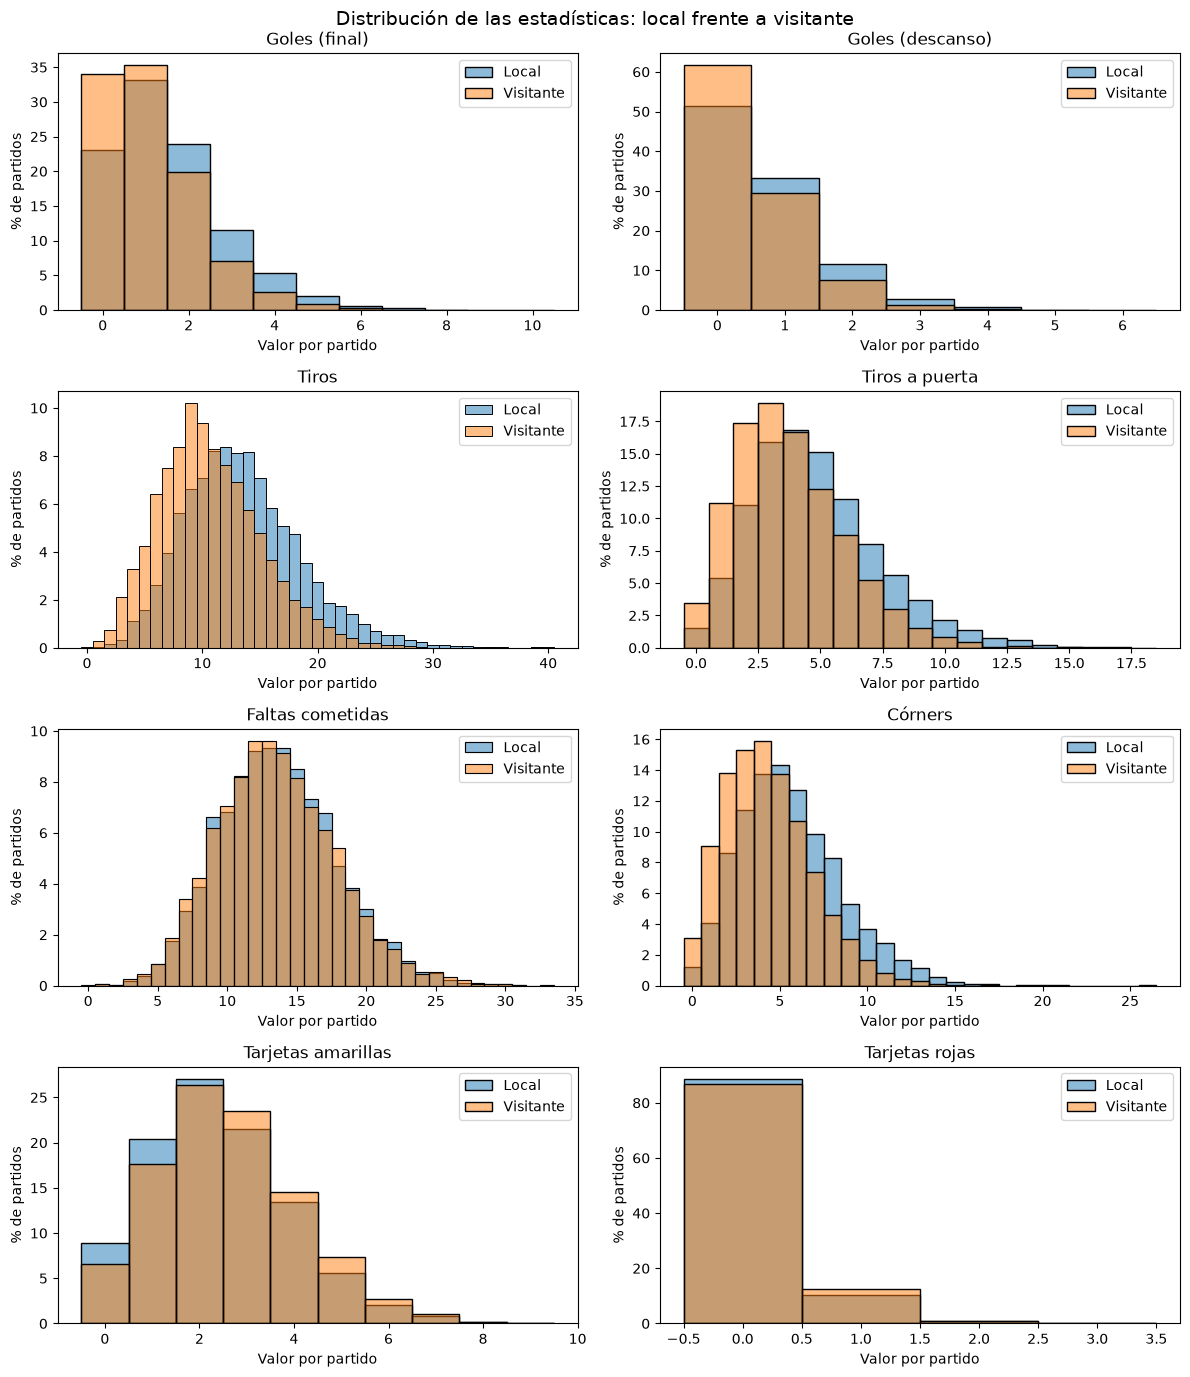

In [180]:
parejas_estadisticas = [("FTHG", "FTAG"), ("HTHG", "HTAG"), ("HS", "AS"), ("HST", "AST"),
                        ("HF", "AF"), ("HC", "AC"), ("HY", "AY"), ("HR", "AR")]

nombres = {"FTHG": "Goles (final)", "HTHG": "Goles (descanso)", "HS": "Tiros",
           "HST": "Tiros a puerta", "HF": "Faltas cometidas", "HC": "Córners",
           "HY": "Tarjetas amarillas", "HR": "Tarjetas rojas"}

cols_estadisticas = [col for pareja in parejas_estadisticas for col in pareja]
display(laliga[cols_estadisticas].describe().round(2))

# Cuadrícula de histogramas: un recuadro por pareja
n_cols = 2
n_filas = int(np.ceil(len(parejas_estadisticas) / n_cols))

fig, axes = plt.subplots(n_filas, n_cols, figsize=(6 * n_cols, 3.5 * n_filas))
axes = axes.flatten()

for (local, visitante), ax in zip(parejas_estadisticas, axes):
    sns.histplot(data=laliga, x=local, discrete=True, stat="percent",
                 alpha=0.5, label="Local", ax=ax)
    sns.histplot(data=laliga, x=visitante, discrete=True, stat="percent",
                 alpha=0.5, label="Visitante", ax=ax)
    ax.set_title(nombres[local])
    ax.set_xlabel("Valor por partido")
    ax.set_ylabel("% de partidos")
    ax.legend()

for ax in axes[len(parejas_estadisticas):]:
    ax.set_visible(False)

fig.suptitle("Distribución de las estadísticas: local frente a visitante", fontsize=14)
plt.tight_layout()
plt.show()

Una vez vistos los parámetros y las gráficas de las estadísticas de todos los partidos, se pueden empezar a sacar conclusiones:
- Los tiros, los tiros a puerta, los goles y los córners es donde más se aprecia la diferencia entre local y visitante.
- El número de faltas y de tarjetas amarillas es muy parecido tanto para los equipos locales como para los visitantes, aunque el visitante recibe algo más (**2.62** frente a **2.41** de media). Por lo tanto, no reflejan la ventaja de jugar en casa. En el siguiente paso del análisis se verá si se relacionan con el resultado final, para ver si la disciplina del equipo afecta al resultado.
- En torno al **90%** de los partidos, un equipo no recibe ninguna tarjeta roja. Como casi siempre va a valer lo mismo, aporta muy poca variación para la red neuronal. Además, son sucesos puntuales, que solo afectan al siguiente partido.
- Al comparar la media de los goles al final del partido, se puede apreciar que el equipo local marca un **36%** más de goles que el equipo visitante, o visto al revés, que el equipo visitante anota un **27%** menos que el equipo local. Esto presenta indicios de que existe la ventaja de jugar en casa.
- Aunque algunas estadísticas, como las faltas y los tiros, se acercan a una normal se puede apreciar que, en general, las estadísticas no siguen una normal y son asimétricas a la derecha. 

In [181]:
# Nombre legible para las 16 columnas (local y visitante)
nombres_completos = {}
for local, visitante in parejas_estadisticas:
    nombres_completos[local] = f"{nombres[local]} (local)"
    nombres_completos[visitante] = f"{nombres[local]} (visitante)"

datos = laliga[cols_estadisticas]
media = datos.mean()
desv = datos.std()
varianza = datos.var()

tabla_asimetria = pd.DataFrame({
    "Media": media,
    "Desv. típica": desv,
    "Media / desv.": media / desv,
    "Varianza / media": varianza / media,
    "Asimetría": datos.skew(),
    "Asimetría Poisson": 1 / np.sqrt(media),
    "% de ceros": (datos == 0).mean() * 100,
})

tabla_asimetria = tabla_asimetria.sort_values("Media / desv.").rename(index=nombres_completos)
display(tabla_asimetria.round(2))

,Media,Desv. típica,Media / desv.,Varianza / media,Asimetría,Asimetría Poisson,% de ceros
Tarjetas rojas (local),0.12,0.35,0.34,1.02,2.95,2.87,88.72
Tarjetas rojas (visitante),0.14,0.38,0.38,0.99,2.62,2.65,86.74
Goles (descanso) (visitante),0.49,0.71,0.69,1.04,1.55,1.43,61.66
Goles (descanso) (local),0.68,0.85,0.81,1.06,1.30,1.21,51.35
Goles (final) (visitante),1.13,1.13,1.00,1.13,1.22,0.94,34.00
Goles (final) (local),1.54,1.33,1.16,1.14,1.05,0.81,23.04
Tarjetas amarillas (local),2.41,1.51,1.60,0.94,0.56,0.64,8.91
Tiros a puerta (visitante),3.74,2.22,1.69,1.31,0.77,0.52,3.43
Tarjetas amarillas (visitante),2.62,1.53,1.71,0.90,0.51,0.62,6.57
Córners (visitante),4.32,2.52,1.71,1.47,0.68,0.48,3.09


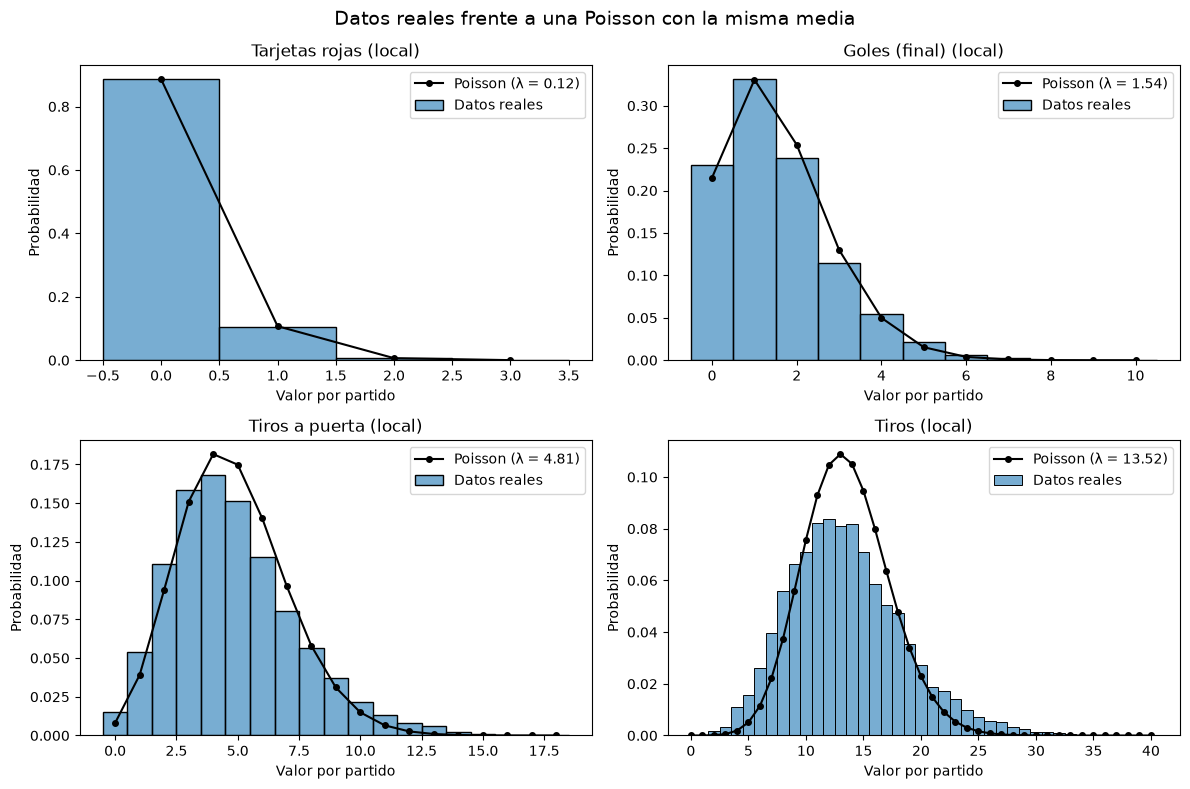

In [182]:
# Cuatro ejemplos representativos: de muy asimétrica a casi simétrica
ejemplos = ["HR", "FTHG", "HST", "HS"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for col, ax in zip(ejemplos, axes):
    sns.histplot(data=laliga, x=col, discrete=True, stat="probability",
                 alpha=0.6, label="Datos reales", ax=ax)

    k = np.arange(0, laliga[col].max() + 1)
    ax.plot(k, poisson.pmf(k, laliga[col].mean()), "o-", color="black",
            markersize=4, label=f"Poisson (λ = {laliga[col].mean():.2f})")

    ax.set_title(nombres_completos[col])
    ax.set_xlabel("Valor por partido")
    ax.set_ylabel("Probabilidad")
    ax.legend()

fig.suptitle("Datos reales frente a una Poisson con la misma media", fontsize=14)
plt.tight_layout()
Path("results").mkdir(exist_ok=True)
fig.savefig("results/poisson_vs_real.png", dpi=150)
plt.show()


- Con este análisis, se puede apreciar el motivo por el cual hay asimetría. Al ser un conteo, siempre va a ser mayor o igual que 0. Entonces, cuanto más cerca del 0 esté la media, más se acumula la distribución en el 0 y más se estira hacia la derecha. Las rojas y los goles son las más asimétricas (asimetría de **2.95** en las rojas del local), mientras que los tiros y las faltas se acercan a una campana (**0.67** y **0.36**). La asimetría teórica de una Poisson $\frac{1}{\sqrt{\lambda}}$, donde $\lambda$ es la media de la estadística, reproduce esa tendencia: cuanto menor es la media, mayor es la asimetría.
- Para comprobar si las estadísticas se parecen a una Poisson, se ha usado su propiedad principal: la varianza es igual a la media, o lo que es lo mismo, el cociente varianza / media vale 1. Además, se ha comparado la asimetría real con la teórica y la distribución real con la de una Poisson de la misma media. Entonces, se distinguen dos grupos:
    - Las rojas, los goles, los goles al descanso y las amarillas se aproximan bien a una Poisson, con un cociente varianza / media entre **0.90** y **1.14**.
    - Los tiros, los córners, los tiros a puerta y las faltas tienen sobredispersión, con un cociente entre **1.31** y **1.90**. Varían más de lo que una Poisson permitiría y tienen una asimetría real mayor que la teórica.
- La sobredispersión ocurre porque la Poisson supone que todos los partidos tienen la misma media, pero como hay equipos mejores y equipos peores, no realizan el mismo número de tiros, por ejemplo. Como se mezclan partidos de equipos con medias muy distintas, la varianza total suma la variación de cada partido más la diferencia entre equipos. Esto último es una prueba, que aportan los datos, acerca de los distintos niveles que tienen los equipos, que justifica justamente lo expuesto anteriormente: la creación de variables que midan el nivel de cada equipo.  
- Estas estadísticas no entran directamente en la red, pero si lo hicieran, la asimetría sería un problema. Al estandarizar, casi todos los partidos se amontonarían en un valor parecido y unos pocos quedarían muy lejos. Como la actualización de cada peso es proporcional al valor de cada entrada, esos pocos partidos dominarían el entrenamiento y llevarían las predicciones a los extremos. Las variables que se van a crear son medias de los últimos 5 partidos, que tendrán valores menos extremos y serán menos asimétricas. Aun así, su asimetría se revisará posteriormente, en la creación de variables, con los datos de entrenamiento, por si hubiera que aplicar una transformación como $\log(1+x)$ antes de estandarizar.

Luego, se analizará las estadísticas que de verdad aporten al resultado (solo con los datos de entrenamiento, para no analizar las estadísticas con los datos del test, porque si no no podríamos analizar de forma real si las estadísticas del pasado pueden inferir en los resultados del futuro). Se mostrará con: 
- Un heatmap para ver la correlación entre variables.
- un group means table 
- un violin plot

In [183]:
# cogemos los datos de entrenamiento del dataset
temporadas_entrenamiento = [1,2,3,4,5,6,7,8,9,10,11,12,13]
mascara_entrenamiento = laliga["Temporada"].isin(temporadas_entrenamiento)
datos_entrenamiento = laliga[mascara_entrenamiento].copy()

Una vez separados los datos de entrenamiento, se van a realizar las columnas con las parejas (local-visitante). Antes de esto, quitamos la columna *FTHG* y *FTAG*, ya que son los goles anotados al final del partido, que siempre van a seguir el resultado final. Si al hacer la resta, sale positivo, significa que el equipo local ha ganado y el resultado es una *H*, y viceversa. No aporta nada para este caso.  
También se van a representar los violin plots de estas diferencias, para visualizarlas gráficamente.

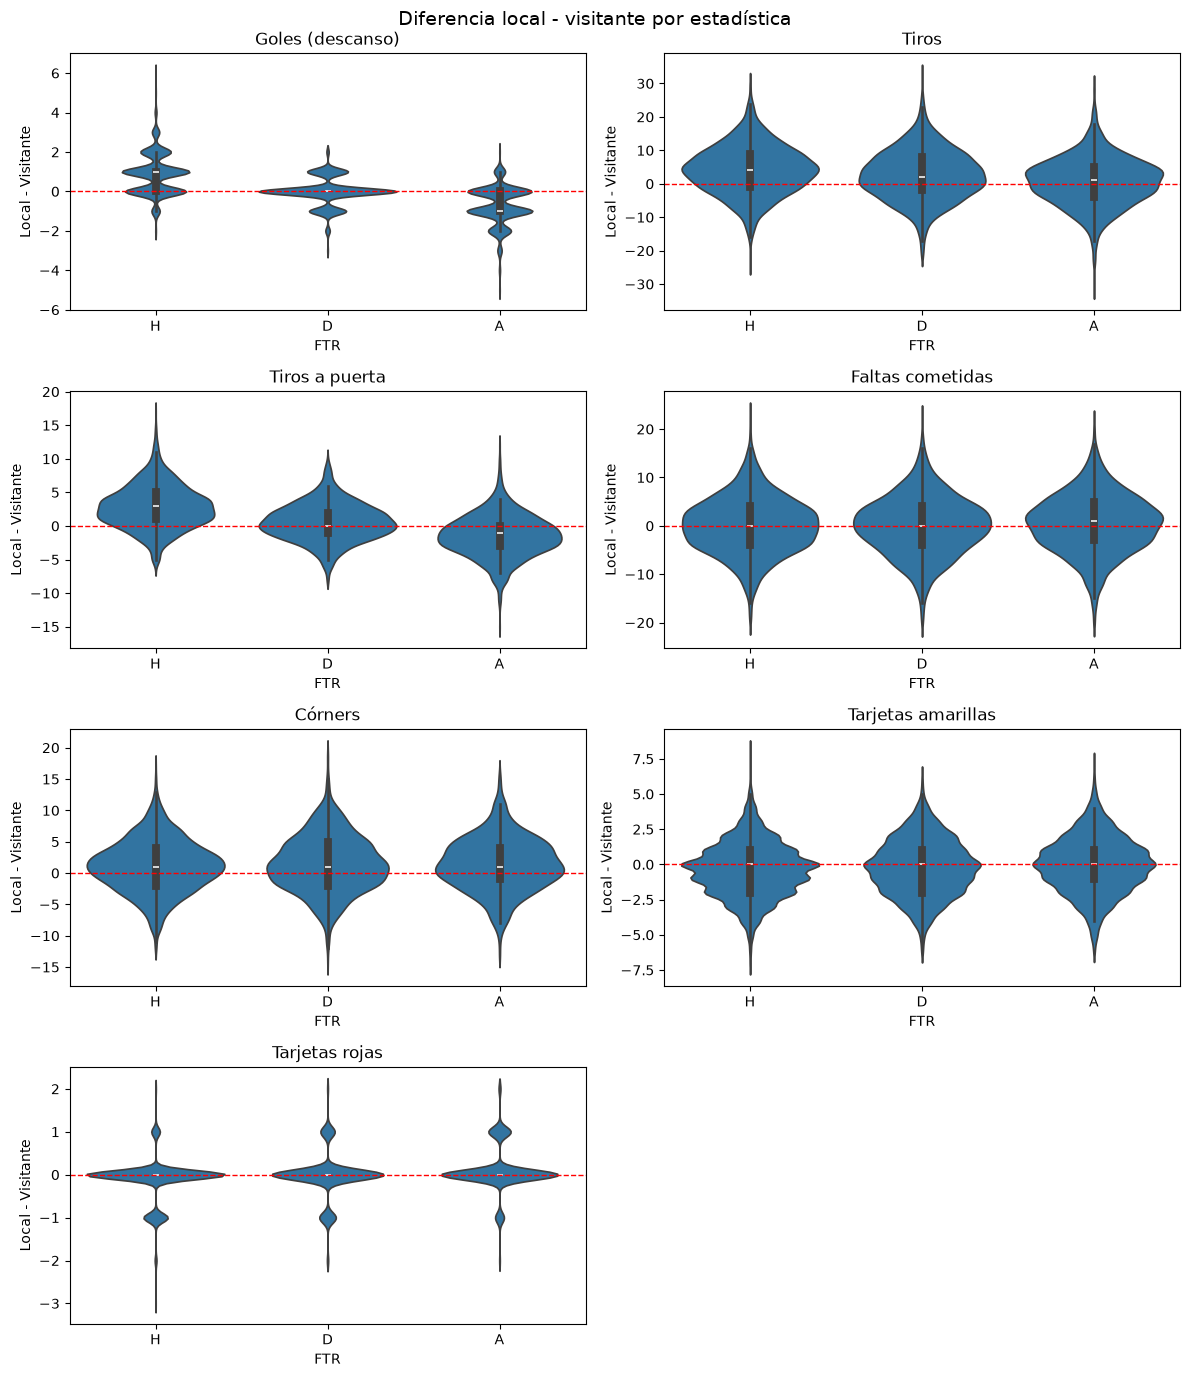

In [184]:
parejas_estadisticas_analisis = [('HTHG', 'HTAG'), ('HS', 'AS'), ('HST', 'AST'), ('HF', 'AF'), ('HC', 'AC'), ('HY', 'AY'), ('HR', 'AR')]

for local, visitante in parejas_estadisticas_analisis:
    datos_entrenamiento[f'{local} - {visitante}'] = datos_entrenamiento[local] - datos_entrenamiento[visitante]

# Cuadrícula de violin plot: un recuadro por pareja
n_cols = 2
n_filas = int(np.ceil(len(parejas_estadisticas_analisis) / n_cols))

fig, axes = plt.subplots(n_filas, n_cols, figsize=(6 * n_cols, 3.5 * n_filas))
axes = axes.flatten()

for (local, visitante), ax in zip(parejas_estadisticas_analisis, axes):
    col = f'{local} - {visitante}'
    sns.violinplot(data=datos_entrenamiento, x="FTR", y=col, order=["H", "D", "A"], ax=ax)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(nombres[local])
    ax.set_ylabel("Local - Visitante")

for ax in axes[len(parejas_estadisticas_analisis):]:
    ax.set_visible(False)

fig.suptitle("Diferencia local - visitante por estadística", fontsize=14)
plt.tight_layout()
plt.show()

Los violines se solapan bastante, lo que hace muy difícil poder predecir un partido con una sola estadística.  
Una vez visto las representaciones de las diferencias, se va a realizar una tabla de medias por resultado.

In [185]:
col_parejas = ["HTHG - HTAG", "HS - AS", "HST - AST", "HF - AF", "HC - AC", "HY - AY", "HR - AR"]
medias_resultado = datos_entrenamiento.groupby("FTR")[col_parejas].mean(numeric_only=True).reindex(["H", "D", "A"]).T

grupos = medias_resultado[["H", "D", "A"]]
medias_resultado["Rango desviaciones"] = (grupos.max(axis=1) - grupos.min(axis=1)) / datos_entrenamiento[col_parejas].std() # diferencia de medias entre desviación típica
medias_resultado["Grupo máx"] = grupos.idxmax(axis=1)
medias_resultado["Grupo mín"] = grupos.idxmin(axis=1)
medias_resultado.sort_values("Rango desviaciones", ascending=False)

FTR,H,D,A,Rango desviaciones,Grupo máx,Grupo mín
HTHG - HTAG,0.847018,-0.009796,-0.695218,1.367050,H,A
HST - AST,2.854797,0.599184,-1.463241,1.195615,H,A
HS - AS,4.184961,2.626122,0.717345,0.464249,H,A
HR - AR,-0.108038,-0.022041,0.107066,0.424241,A,H
HY - AY,-0.357390,-0.200816,-0.024268,0.170821,A,H
HC - AC,1.153846,1.488163,1.389722,0.078014,D,H
HF - AF,0.089888,0.026122,0.478230,0.076253,A,D


La forma de leer esta tabla es mirando la progresión de la media. Pero como no están en la misma escala, se ha tenido que aplicar una diferencia de medias entre la desviación típica, para poder comparar las columnas.
- Los goles en la primera parte y los tiros a puerta son los que más rango tienen, que son los que más separan unos resultados de otros.
- Los tiros y las rojas son las siguientes en la tabla, que implican que tienen también bastante importancia a la hora de relacionarse con un resultado.
- Las amarillas, los córners y las faltas se puede ver que no tienen tanto que ver con el resultado, y que suceden de forma parecida sin importar el resultado final.
- Como el grupo máximo en las rojas y en las amarillas es A y el mínimo H, esto explica que el equipo que pierde suele tener más rojas y amarillas de media.
- En los córners sucede que el máximo está en D y el mínimo en H. Una posible explicación puede ser que cuando el equipo local quiere ir a por el partido, suele echarse mucho más al ataque para poder remontar el partido, provocando más córners. Lo mismo puede pasar con las faltas aunque sus extremos sean A y D, ya que cuando hay empate el número de faltas es parejo, pero cuando el local va perdiendo, al subir la intensidad, también provocan más faltas.

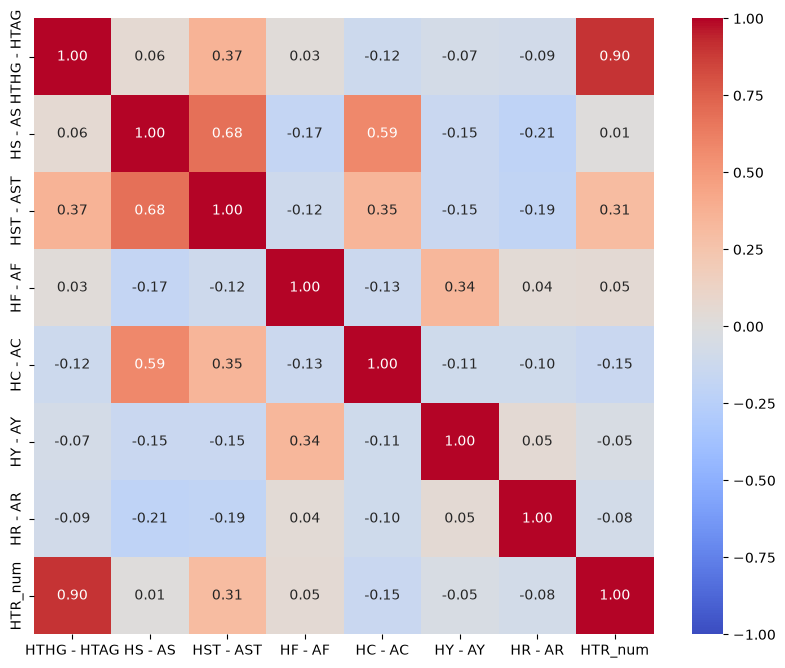

In [186]:
datos_entrenamiento["HTR_num"] = datos_entrenamiento["HTR"].map({"H": 1, "D": 0, "A": -1})
col_corr = col_parejas + ["HTR_num"]
corr = datos_entrenamiento[col_corr].corr()

fig, ax = plt.subplots(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
plt.show()

Tras analizar este mapa de correlación, se ha llegado a la conclusión de que se va a quitar *HTR* porque es lo mismo que pasa con el resultado final, que dependiendo del signo de la diferencia entre goles del local y del visitante en la primera mitad, el resultado va a ir de la mano.  
El resto de estadísticas no pasan del umbral de > 0.8, por tanto, se dejan. Pero las que están entre 0.5 y 0.8 hay que vigilarlas (tiros-tiros a puerta 0.68 y tiros-córners 0.59) porque podrían suponer un problema para los coeficientes de la regresión logística.

Estas estadísticas son del propio partido y el marcador influye en ellas. Por eso la relación puede ir en ambas direcciones. Entonces, esta selección es provisional y se volverá a analizar con las medias de los 5 partidos anteriores en la fase de variables.  
Por lo tanto, para la forma se usarán los tiros, los tiros a puerta, los puntos y los goles tanto a la mitad como al final (en este análisis se habían quitado porque es circular comparar los goles finales con el resultado, pero sí son importantes para la forma) y se descartan el resultado a la mitad del partido, los córners, las faltas y las tarjetas, ya que una tarjeta roja es relevante en un partido, pero no influye igual para la forma de un equipo en 5 partidos. 

Ahora se van a calcular las frecuencias de victoria local, empato o visitante con un bar chart, mostrando el porcentaje.

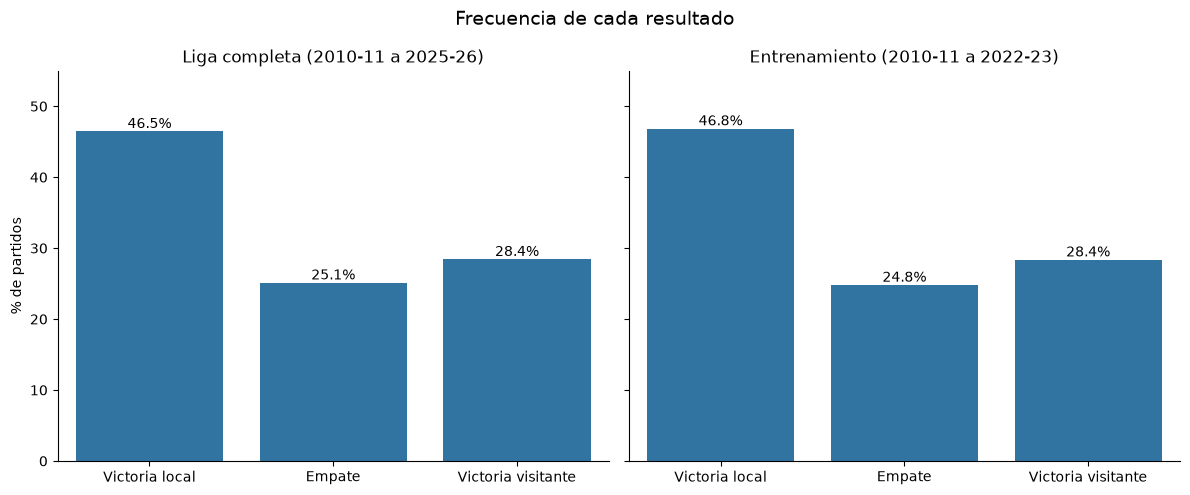

In [187]:
frecuencias = laliga.value_counts("FTR", normalize=True).reindex(["H", "D", "A"]) # frecuencias en la liga completa
frecuencias_entrenamiento = datos_entrenamiento.value_counts("FTR", normalize=True).reindex(["H", "D", "A"]) # frecuencias en entrenamiento
frecuencias = frecuencias * 100
frecuencias_entrenamiento = frecuencias_entrenamiento * 100

conjuntos = [(frecuencias, "Liga completa (2010-11 a 2025-26)"),
             (frecuencias_entrenamiento, "Entrenamiento (2010-11 a 2022-23)")]
etiquetas = ["Victoria local", "Empate", "Victoria visitante"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for (serie, titulo), ax in zip(conjuntos, axes):
    sns.barplot(x=serie.index, y=serie.values, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_xticks(range(len(etiquetas)), labels=etiquetas)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("% de partidos")

axes[0].set_ylim(0, 55)
sns.despine()
fig.suptitle("Frecuencia de cada resultado", fontsize=14)
plt.tight_layout()
fig.savefig("results/frecuencia_resultados.png", dpi=150)
plt.show()

Esta es la descripción de todas las temporadas, aunque luego para nuestro modelo trivial usaremos solo las temporadas de entrenamiento. Los porcentajes como se ve, no varían mucho (local 46.5% - 46.8%, empate 25.1% - 24.8% y visitante 28.4% - 28.4%), ya que el 84% de los partidos son los datos de entrenamiento.  
- El resultado menos frecuente es el empate (25.1%), seguido de la victoria visitante (28.4%) y de la victoria local (46.5%). 
- El porcentaje de resultados está desigualado, pero no se puede cambiar. Las cuotas de nuestra casa de apuestas van en función del porcentaje del resultado final. Si entrenamos con las clases rebalanceadas estaríamos poniendo cuotas que no se ajustan a la realidad, ya que se sobreestimaría la probabilidad de empate.
- El empate es la clase menos frecuente, por lo tanto, será la clase más difícil de predecir.
- Esto muestra que jugar en casa puede suponer una ventaja, como ya habíamos visto con la diferencia de los goles al final del partido.
- Si apostases siempre al local, acertarías en el 46.5% de las veces, casi una de dos apuestas resultarían ganadoras.

Una vez analizadas las frecuencias de resultados, ahora se debe analizar si estas frecuencias varían con el tiempo y para eso se usará un linechart. Hay que tener en cuenta que hubo una temporada y media en la que no hubo público y puede que afectase para estas frecuencias. Además, se analizará también por equipo.

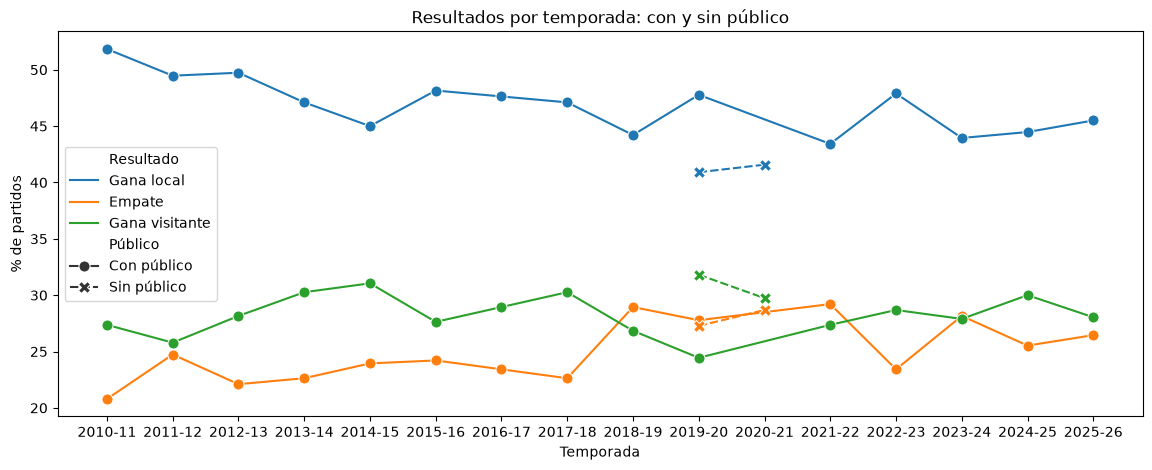

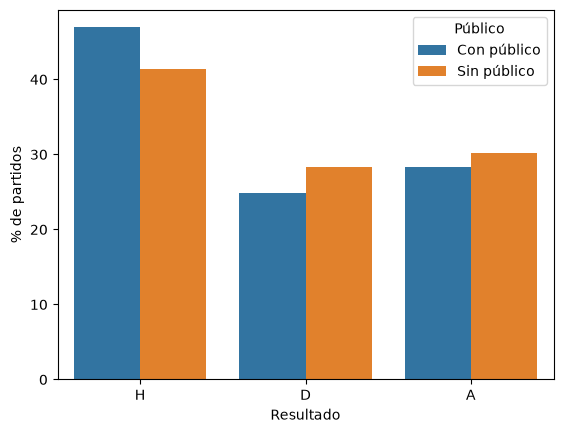

In [188]:
# ventaja local por temporada
# primero separamos temporadas con cierre y sin cierre
temporada_10 = laliga[laliga["Temporada"] == 10].copy()
indice_salto = temporada_10["Date"].diff().idxmax()
fecha_corte = temporada_10.loc[indice_salto, "Date"] # 3690, aquí se reanudó la liga
mascara_sin_publico = ((laliga["Temporada"] == 11) | (temporada_10["Date"] >= fecha_corte)) 

partidos_sin_publico = laliga[mascara_sin_publico]
partidos_con_publico = laliga[~mascara_sin_publico]

evolucion_sin_publico = partidos_sin_publico.groupby("Temporada")["FTR"].value_counts(normalize=True).unstack().reindex(columns=["H", "D", "A"])
evolucion_con_publico = partidos_con_publico.groupby("Temporada")["FTR"].value_counts(normalize=True).unstack().reindex(columns=["H", "D", "A"])

# evolución a lo largo de las temporadas
largo = (
    pd.concat([evolucion_con_publico.assign(Público="Con público"), evolucion_sin_publico.assign(Público="Sin público")]).reset_index()
    .melt(id_vars=["Temporada", "Público"], var_name="Resultado", value_name="Proporción")
)
largo["Proporción"] *= 100
largo["Resultado"] = largo["Resultado"].map({"H": "Gana local", "D": "Empate", "A": "Gana visitante"})


fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=largo, x="Temporada", y="Proporción", hue="Resultado", style="Público", markers=True, markersize=8, ax=ax)
ax.set_ylabel("% de partidos")
ax.set_title("Resultados por temporada: con y sin público")
ax.set_xticks(sorted(largo["Temporada"].unique()), labels=["2010-11", "2011-12", "2012-13", "2013-14", "2014-15", "2015-16", "2016-17", "2017-18", "2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25", "2025-26"])
plt.show()

# comparación directa entre con público y sin público
global_ = pd.concat([partidos_con_publico["FTR"].value_counts(normalize=True).rename("Con público"),
    partidos_sin_publico["FTR"].value_counts(normalize=True).rename("Sin público"),
], axis=1).reindex(["H", "D", "A"]).mul(100).reset_index(names="Resultado")

sns.barplot(data=global_.melt(id_vars="Resultado", var_name="Público", value_name="%"), x="Resultado", y="%", hue="Público")
plt.ylabel("% de partidos")
plt.show()

- En el linechart, se puede ver una tendencia de que la ventaja local cada vez es menor, pero sigue siendo alta respecto a las probabilidades de otros resultados. Entre 2010 y 2013 el porcentaje de victoria local se situaba en torno al 50%. Actualmente, este porcentaje oscila entre el 43% y el 48%.
- La temporada y media sin público hizo que el porcentaje de victoria local bajase hasta el 41%, pero la victoria visitante subió un poco más que el 30%. Los empates se subieron a un 28%. Por tanto, el porcentaje perdido de las victorias locales se fue un 2% a las victorias visitantes y casi un 4% a los empates. Como la ventaja local se siguió mostrando incluso sin público, esto puede indicar que no solo es el público a favor lo que provoca esta ventaja local.
- Como la ventaja local ha ido bajando, pero se va a entrenar el modelo con datos donde la ventaja era más alta, seguramente la ventaja influirá más en el modelo de lo que debería.
  
Ahora veremos si los equipos también mantienen la misma ventaja local, ya que si lo hacen, esta variable dejaría de aportar nueva información. 

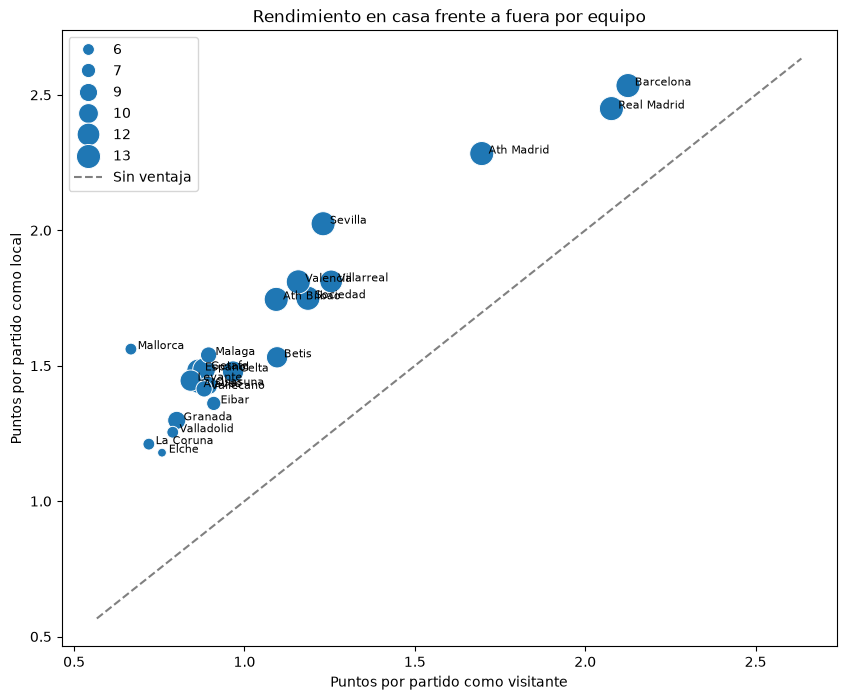

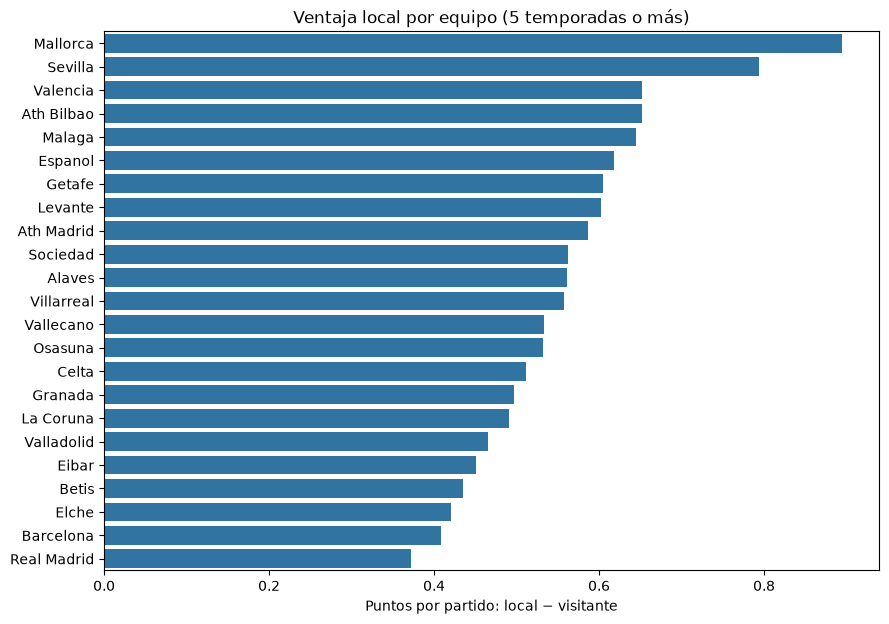

Diferencias reales entre equipos (desv. típica): 0.122
Error esperado solo por azar (media de los equipos): 0.140


In [189]:
# ventaja local de cada equipo en un conjunto de partidos
def ventaja_local(df):
    puntos_local = df["FTR"].map({"H": 3, "D": 1, "A": 0})
    puntos_visitante = df["FTR"].map({"H": 0, "D": 1, "A": 3})

    tabla = pd.concat([puntos_local.groupby(df["HomeTeam"]).mean().rename("Local"), puntos_visitante.groupby(df["AwayTeam"]).mean().rename("Visitante"),
        df.groupby("HomeTeam").size().rename("Partidos"), df.groupby("HomeTeam")["Temporada"].nunique().rename("Temporadas")], axis=1)
    tabla["Ventaja local"] = tabla["Local"] - tabla["Visitante"]
    return tabla

ventaja_equipos = ventaja_local(datos_entrenamiento)
ventaja_equipos = ventaja_equipos[ventaja_equipos["Temporadas"] >= 5]

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=ventaja_equipos, x="Visitante", y="Local", size="Temporadas", sizes=(40, 300), ax=ax)
limites = [ventaja_equipos[["Local", "Visitante"]].min().min() - 0.1, ventaja_equipos[["Local", "Visitante"]].max().max() + 0.1]
ax.plot(limites, limites, "--", color="grey", label="Sin ventaja")

for equipo, fila in ventaja_equipos.iterrows():
    ax.text(fila["Visitante"] + 0.02, fila["Local"], equipo, fontsize=8)
ax.set_xlabel("Puntos por partido como visitante")
ax.set_ylabel("Puntos por partido como local")
ax.set_title("Rendimiento en casa frente a fuera por equipo")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=ventaja_equipos.sort_values("Ventaja local", ascending=False).reset_index(names="Equipo"),
            x="Ventaja local", y="Equipo", ax=ax)
ax.set_xlabel("Puntos por partido: local − visitante")
ax.set_ylabel("")
ax.set_title("Ventaja local por equipo (5 temporadas o más)")
plt.show()

# ¿Las diferencias entre equipos son mayores que las que daría el azar?
sigma = datos_entrenamiento["FTR"].map({"H": 3, "D": 1, "A": 0}).std()
error_azar = sigma * np.sqrt(2 / ventaja_equipos["Partidos"])
print(f"Diferencias reales entre equipos (desv. típica): {ventaja_equipos['Ventaja local'].std():.3f}")
print(f"Error esperado solo por azar (media de los equipos): {error_azar.mean():.3f}")

Equipos en las dos mitades: 18
Correlación entre la ventaja local antigua y la reciente: 0.27


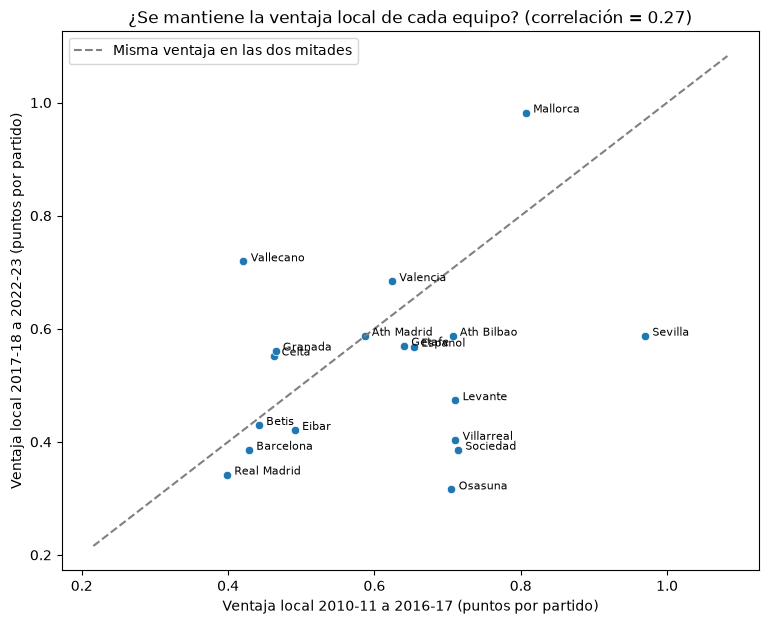

In [190]:
# ¿La ventaja local de un equipo en el pasado se mantiene en el futuro?
antiguas = ventaja_local(datos_entrenamiento[datos_entrenamiento["Temporada"] <= 7])
recientes = ventaja_local(datos_entrenamiento[datos_entrenamiento["Temporada"] >= 8])

comparacion = pd.concat([antiguas["Ventaja local"].rename("Antiguas"), antiguas["Temporadas"].rename("Temporadas antiguas"), recientes["Ventaja local"].rename("Recientes"),
                          recientes["Temporadas"].rename("Temporadas recientes")], axis=1).dropna()
comparacion = comparacion[(comparacion["Temporadas antiguas"] >= 3) & (comparacion["Temporadas recientes"] >= 3)]

correlacion = comparacion["Antiguas"].corr(comparacion["Recientes"])
print(f"Equipos en las dos mitades: {len(comparacion)}")
print(f"Correlación entre la ventaja local antigua y la reciente: {correlacion:.2f}")

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=comparacion, x="Antiguas", y="Recientes", ax=ax)
limites = [comparacion[["Antiguas", "Recientes"]].min().min() - 0.1, comparacion[["Antiguas", "Recientes"]].max().max() + 0.1]
ax.plot(limites, limites, "--", color="grey", label="Misma ventaja en las dos mitades")
for equipo, fila in comparacion.iterrows():
    ax.text(fila["Antiguas"] + 0.01, fila["Recientes"], equipo, fontsize=8)
ax.set_xlabel("Ventaja local 2010-11 a 2016-17 (puntos por partido)")
ax.set_ylabel("Ventaja local 2017-18 a 2022-23 (puntos por partido)")
ax.set_title(f"¿Se mantiene la ventaja local de cada equipo? (correlación = {correlacion:.2f})")
ax.legend()
plt.show()


Para analizar si la ventaja local depende del equipo, solo se han tenido en cuenta los equipos con **5 temporadas o más** en el conjunto de entrenamiento (**23 equipos**). Con menos temporadas, el error de la ventaja local de un equipo es demasiado grande: con una sola temporada (19 partidos en casa y 19 fuera) sería de unos **±0.42** puntos por partido, mientras que con 5 temporadas baja a unos **±0.19**. Como medida de la ventaja local se usa la diferencia entre los puntos por partido en casa y fuera.

- En el scatter plot, todos los equipos quedan por encima de la diagonal, lo que confirma que la ventaja local existe en LaLiga. Los equipos más fuertes, como el Real Madrid y el Barcelona, son los que menos ventaja local tienen, porque ganan casi siempre, jueguen donde jueguen, y les queda poco margen para ganar más en casa.
- Para saber si las diferencias entre equipos son reales, se ha comparado su dispersión con la que habría solo por azar. La desviación típica de la ventaja local entre equipos es de **0.122**, mientras que el error esperado solo por azar es de **0.140**. Es decir, aunque todos los equipos tuvieran exactamente la misma ventaja local, por pura casualidad ya se verían diferencias de este tamaño.
- Además, se ha comparado la ventaja local de cada equipo entre las temporadas antiguas (2010-11 a 2016-17) y las recientes (2017-18 a 2022-23), con los **18 equipos** que tienen al menos 3 temporadas en cada mitad. Si la ventaja local fuera una característica propia de cada equipo, el que la tenía alta en el pasado la seguiría teniendo alta después. La correlación entre ambas es de solo **0.27**. Por ejemplo, el Sevilla, que era el equipo con más ventaja local en la primera época (**0.97**), bajó a **0.59**, en la media del resto. Esto es una regresión a la media: parte de lo que parecía una fortaleza en casa era suerte.
- La mayoría de los equipos quedan por debajo de la diagonal en el segundo gráfico, lo que coincide con la bajada general de la ventaja local con el paso del tiempo vista en el linechart.

En conclusión, la ventaja local existe y es clara, pero no hay pruebas de que sea distinta para cada equipo: las diferencias entre equipos son del tamaño del ruido y no se mantienen en el tiempo. Esto contradice la idea inicial de que hay equipos especialmente fuertes en su estadio y flojos fuera, que era el motivo para crear la variable de puntos en casa y puntos fuera.

Por lo tanto, la variable de puntos del local en casa y del visitante fuera se mantiene de forma **provisional**. Se compararán dos versiones de la regresión logística, una con esta variable y otra sin ella, sobre el conjunto de validación. Si no mejora el log loss, se eliminará, para que el modelo sea más sencillo. La ventaja local común a todos los equipos no necesita una variable propia, porque la red la puede aprender por sí sola, ya que las variables del local y del visitante entran en columnas distintas.

Ver el rendimiento de los recién ascendidos, viendo los puntos que consiguen en sus temporadas de ascenso. También se va a comparar si puntúan igual que los equipos que descienden la temporada anterior, para ver si es verdad la suposición que se ha hecho anteriormente, de que los equipos recién ascendidos rinden parecido que los equipos recién descendidos.

,mean,median,std,count
Grupo,,,,
Descendido,0.85,0.87,0.16,36
Ascendido,1.08,1.08,0.23,36
Resto,1.43,1.30,0.46,204


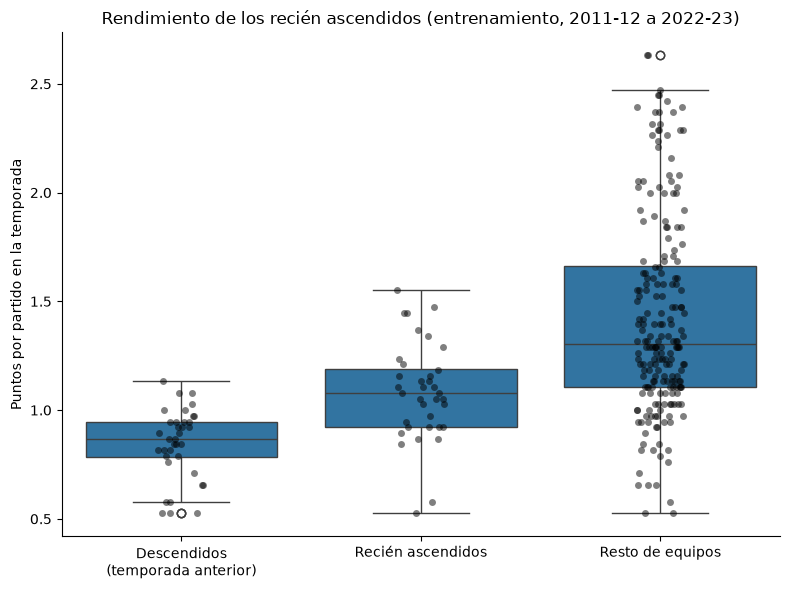

In [191]:
# cogemos los equipos que se mueven y los que no
equipos = datos_entrenamiento.groupby("Temporada")["HomeTeam"].unique()
set_equipos_ascendidos = set()
set_equipos_descendidos = set()
set_equipos_resto = set()

# con esto hacemos los conjuntos de ascendidos, descendidos y el resto (sin ascendidos).
for t in equipos.index[1:]:
    nuevos = set(equipos[t])
    antiguos = set(equipos[t-1])
    for equipo in nuevos - antiguos:
        set_equipos_ascendidos.add((t, equipo)) # empiezan en temporada 2
    for equipo in antiguos - nuevos:
        set_equipos_descendidos.add((t-1, equipo)) # empiezan en temporada 1
    for equipo in nuevos & antiguos:
        set_equipos_resto.add((t, equipo))


tabla_ascendidos = pd.DataFrame(sorted(set_equipos_ascendidos), columns=["Temporada", "Equipo"]).assign(Grupo="Ascendido")
tabla_descendidos = pd.DataFrame(sorted(set_equipos_descendidos), columns=["Temporada", "Equipo"]).assign(Grupo="Descendido")
tabla_resto = pd.DataFrame(sorted(set_equipos_resto), columns=["Temporada", "Equipo"]).assign(Grupo="Resto")


# separamos los partidos por equipo
partidos = datos_entrenamiento.assign(Local=datos_entrenamiento["HomeTeam"], Visitante=datos_entrenamiento["AwayTeam"]).melt(id_vars=list(datos_entrenamiento.columns),
                        value_vars=["Local", "Visitante"], var_name="Condición", value_name="Equipo")
# calculamos los puntos por equipo
puntos_local = {"H": 3, "D": 1, "A": 0}
puntos_visitante = {"H": 0, "D": 1, "A": 3}
partidos["Puntos"] = partidos["FTR"].map(puntos_local).where(partidos["Condición"] == "Local", partidos["FTR"].map(puntos_visitante))
puntos_temporada = partidos.groupby(["Temporada", "Equipo"])["Puntos"].mean().reset_index(name="Puntos/partido")

# creamos las tablas por grupo (ascendidos, descendidos, resto)
tabla_ascendidos = tabla_ascendidos.merge(puntos_temporada, on=["Temporada", "Equipo"])
tabla_descendidos = tabla_descendidos.merge(puntos_temporada, on=["Temporada", "Equipo"])
tabla_resto = tabla_resto.merge(puntos_temporada, on=["Temporada", "Equipo"])

orden = ["Descendido", "Ascendido", "Resto"]
grupos = pd.concat([tabla_ascendidos, tabla_descendidos, tabla_resto], ignore_index=True)

resumen = grupos.groupby("Grupo")["Puntos/partido"].agg(["mean", "median", "std", "count"]).reindex(orden)
display(resumen.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=grupos, x="Grupo", y="Puntos/partido", order=orden, ax=ax)
sns.stripplot(data=grupos, x="Grupo", y="Puntos/partido", order=orden, color="black", alpha=0.5, ax=ax)
ax.set_xticks(range(len(orden)), labels=["Descendidos\n(temporada anterior)", "Recién ascendidos", "Resto de equipos"])
ax.set_xlabel("")
ax.set_ylabel("Puntos por partido en la temporada")
ax.set_title("Rendimiento de los recién ascendidos (entrenamiento, 2011-12 a 2022-23)")
sns.despine()
plt.tight_layout()
fig.savefig("results/rendimiento_ascendidos.png", dpi=150)
plt.show()

- Los recién ascendidos consiguen de media 1.08 puntos por partido, respecto a los 1.43 puntos por partido que consiguen el resto de los equipos de esa misma temporada. Esto indica que de media rinden peor, consiguiendo 0.35 puntos menos por partido, unos 13.3 puntos menos por temporada. Esto justifica que tengan un ELO inicial más bajo que el bloque de equipos que se mantienen en la categoría.
- Contrario a lo que se había supuesto, que los ascendidos rendían parecido a los descendidos, se puede ver con los datos que los descendidos consiguen 0.85 puntos por partido de media, en cambio, los ascendidos consiguen 1.08 puntos por partido, una diferencia de 0.23 puntos por partido, unos 8.74 puntos por temporada. Por tanto, no podemos otorgar a los ascendidos el valor estándar de la media de los descendidos la temporada anterior, ya que la forma inicial de un ascendido saldría demasiado baja. Se usará como valor estándar para un recién ascendido la media acumulada de los ascendidos las temporadas anteriores.
- Al comparar la variabilidad de los datos de los ascendidos (0.23) con los del resto de equipos (0.46) se puede apreciar que varían más los del resto de equipos, porque incluye al campeón de liga y a los equipos que descienden. Sin embargo, los ascendidos son un grupo de equipos que vienen de Segunda división con un nivel parecido.
- Analizando los grupos de los ascendidos y descendidos de cada temporada, se pueden ver que 7 de los 36 equipos ascendidos (19%) descendieron ese mismo año. Esto ayuda a reforzar la idea de los puntos ELO a los ascendidos, que deberían estar por debajo de la media pero por encima de los recién descendidos, ya que 4 de cada 5 equipos que ascienden, se quedan.
- Sacando la tabla de la liga del año 2009-2010 de https://www.bdfutbol.com/es/t/t2010-11.html se puede ver que los recién ascendidos para la temporada 2010-11 son Hércules, Real Sociedad y Levante. Entonces, se cogerán los puntos de estos equipos como valor estándar para los ascendidos de la siguiente temporada.

En esta sección se va a comprobar el margen que se llevan las casas de apuestas *Bet365* y *Pinnacle*, aplicando las fórmulas con las que se calcula el margen.

Frecuencia de victoria para el favorito, suponiendo que el favorito es el que ha sido elegido por las casas de apuesta. Con un bar chart.

Si las casas aciertan sus probabilidades (solo con los datos de entrenamiento). Esto lo haría con group means table y violin chart (no estoy seguro).

### Creación de variables

### Análisis exploratorio de las variables creadas

### Partidos sin historial

### División del dataset

### Normalizar los valores de los vectores